In [2]:
import json
import numpy as np
import torch
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from utils import NEURON_INTERVENTIONS_DIR, ANALYSIS_DIR, DATA_DIR
from utils import set_style, FONT_SIZES, save_plot
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

set_style()

In [3]:
# man_dir = np.load(INTERVENTIONS_DIR / "man_direct.npy", mmap_mode="r")
# man_ind = np.load(INTERVENTIONS_DIR / "man_indirect.npy", mmap_mode="r")
# wom_dir = np.load(INTERVENTIONS_DIR / "woman_direct.npy", mmap_mode="r")
# wom_ind = np.load(INTERVENTIONS_DIR / "woman_indirect.npy", mmap_mode="r")


# def open_file(condition: str):
#     filepath = (INTERVENTIONS_DIR / f"{condition}.txt")
#     return filepath.read_text().splitlines()


# man_dir_ids = open_file("man_direct")
# man_ind_ids = open_file("man_indirect")
# wom_dir_ids = open_file("woman_direct")
# wom_ind_ids = open_file("woman_indirect")


# examples = pd.read_json(EXAMPLES_DIR / "examples.json")

# id_row = {row: id
#           for id, row in enumerate(man_dir_ids)}



In [4]:
def matched_pair(condition, examples):
    """Return examples completed in both direct and indirect conditions."""
    gender = "man" if condition == "man" else "woman"
    direct = load_condition(f"{gender}_direct", examples)
    indirect = load_condition(f"{gender}_indirect", examples)

    return [
        (direct[example_id], indirect[example_id])
        for example_id in direct
    ]


def load_processed_ids(condition):
    filepath = NEURON_INTERVENTIONS_DIR / f"{condition}.txt"
    return set(filepath.read_text().splitlines())


def total_profession_bias(example):
    """The original scripts use definitionality + stereotypicality."""
    return float(example["definitionality"]) + float(example["stereotypicality"])


def load_condition(condition, examples):
    """Return {example_id: (example, patched_scores)} for completed rows."""
    filepath = NEURON_INTERVENTIONS_DIR / f"{condition}.npy"
    effects = np.load(filepath, mmap_mode="r")

    processed_ids = load_processed_ids(condition)

    result = {}
    for row_index, example in enumerate(examples):
        example_id = example["id"]
        if example_id in processed_ids:
            result[example_id] = (example, np.asarray(effects[row_index]))

    return result


def paired_neuron_effects(example, dir_scores, ind_scores, gender):
    prof_baseline = float(example["baseline_m"]["profession"])
    dir_ratio = log_ratio_from_patch(dir_scores, prof_baseline, gender)
    ind_ratio = log_ratio_from_patch(ind_scores, prof_baseline, gender)

    total_causal_effect = dir_ratio + ind_ratio
    return dir_ratio, ind_ratio, total_causal_effect


def log_ratio_from_patch(patched_logit_diff, profession_logit_diff, gender):
    if gender == "woman":
        # (she/he under patch) / (she/he for profession)
        delta = patched_logit_diff - profession_logit_diff
    else:
        # (he/she under patch) / (he/she for profession)
        delta = profession_logit_diff - patched_logit_diff

    return delta


with open(DATA_DIR / "examples.json", "r") as f:
    examples = json.load(f)

Neuron Aggregation Effect

In [5]:
rows = []
example_count = 0
for gender in ("man", "woman"):
    for (example, dir_scores), (_, ind_scores) in matched_pair(gender, examples):
        if abs(float(example["definitionality"])) <= 0.75:
            continue

        bias = total_profession_bias(example)
        if gender == "man" and not bias < 0:
            continue
        if gender == "woman" and not bias >= 0:
            continue

        example_count += 1

        r = paired_neuron_effects(example, dir_scores, ind_scores, gender)
        dir_ratio, ind_ratio, total_effect = r

        n_modules, n_neurons = dir_ratio.shape
        for module in range(n_modules):
            for neuron in range(n_neurons):
                rows.append(
                    {
                        "example_id": str(example["id"]),
                        "profession": example["profession"],
                        "template": example["template"],
                        "layer": module,
                        "neuron": neuron,
                        "log_ratio_dir": float(dir_ratio[module, neuron]),
                        "log_ratio_ind": float(ind_ratio[module, neuron]),
                        "total_causal_effect": float(
                            total_effect[module, neuron]
                        ),
                    }
                )

df = pd.DataFrame(rows)
df["neuron_key"] = df["layer"].astype(str) + "-" + df["neuron"].astype(str)

summary = (
    df.groupby("neuron_key", as_index=False)
    .agg(
        layer=("layer", "mean"),
        neuron=("neuron", "mean"),

        log_ratio_ind_mean=("log_ratio_ind", "mean"),
        log_ratio_ind_std=("log_ratio_ind", "std"),

        log_ratio_dir_mean=("log_ratio_dir", "mean"),
        log_ratio_dir_std=("log_ratio_dir", "std"),

        total_causal_effect_mean=("total_causal_effect", "mean"),
        total_causal_effect_std=("total_causal_effect", "std"),
    )
    .drop(columns="neuron_key")
)

summary.to_csv(ANALYSIS_DIR / "neuron_effects.csv", index=False)
example_count

187

In [11]:
summary.max()

layer                        12.000000
neuron                      767.000000
log_ratio_ind_mean            0.052260
log_ratio_ind_std             0.082357
log_ratio_dir_mean            4.847340
log_ratio_dir_std             1.641997
total_causal_effect_mean      4.894966
total_causal_effect_std       1.636743
dtype: float64

Neuron Effect Per Layer

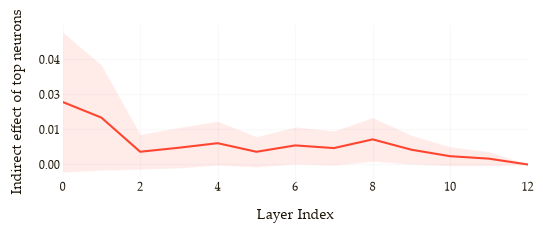

In [26]:
PERCENT = 5
rows = []
df = pd.read_csv(ANALYSIS_DIR / "neuron_effects.csv")

for layer, layer_df in df.groupby("layer"):
    n_neurons = len(layer_df)
    top_count = max(1, int(n_neurons * PERCENT / 100.0))
    rows.append(layer_df.nlargest(top_count,
                                  "log_ratio_ind_mean"))

top = pd.concat(rows, ignore_index=True)
top = (top
       .groupby("layer", as_index=False)
       .agg(log_ratio_ind_mean=("log_ratio_ind_mean", "mean"),
            log_ratio_ind_std=("log_ratio_ind_std", "mean"))
       )

plt.figure(figsize=(6, 2))
x = top["layer"].to_numpy()
y = top["log_ratio_ind_mean"].to_numpy()
std = top["log_ratio_ind_std"].to_numpy()

ax = sns.lineplot(x=x, y=y)
ax.tick_params(axis='both', which='major', pad=-4)
plt.fill_between(x, y - std, y + std, alpha=0.1)
plt.xlabel("Layer Index")
plt.ylabel("Indirect effect of top neurons")
sns.despine(left=True, bottom=True)
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=5))
plt.xlim(x.min(), x.max())
# plt.ylim(y.min(), 0.05)
save_plot("indirect_effect_of_top_neurons")
plt.show()

The total effect of this model is  -2.235
The total (male) effect of this model is  -2.533
The total (female) effect of this model is  2.722
The correlation between bias value and (log) effect is 0.52 (p=0.000)


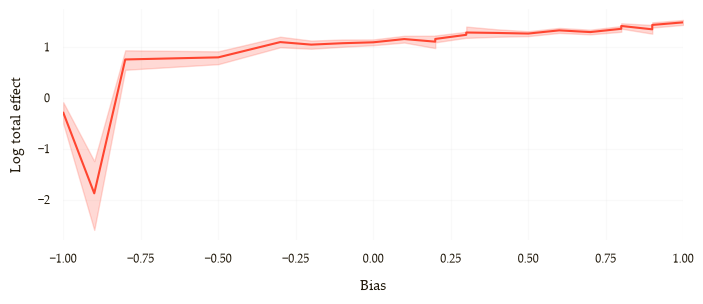

In [ ]:
from scipy.stats import pearsonr


def total_effects(example):
    baseline = example["baseline_m"]
    profession = baseline["profession"]
    man = baseline["man"]
    woman = baseline["woman"]

    # Candidate 1 is "he", candidate 2 is "she".
    he_total = profession - man
    she_total = woman - profession

    # Original selects the direction matching the profession baseline odds.
    selected = he_total if profession <= 0 else she_total
    return float(he_total), float(she_total), float(selected)


rows = []
for example in examples:
    he_total, she_total, selected_total = total_effects(example)
    rows.append({
        "example_id": str(example["id"]),
        "profession": example["profession"],
        "definitionality": float(example["definitionality"]),
        "bias": total_profession_bias(example),
        "he_total_effect": he_total,
        "she_total_effect": she_total,
        "total_effect": selected_total,
    })

df = pd.DataFrame(rows)
filtered = df[df["definitionality"].abs() < 0.75]
print(f"The total effect of this model is ",
      f"{filtered['total_effect'].mean() - 1:.3f}")
print(f"The total (male) effect of this model is ",
      f"{filtered['he_total_effect'].mean() - 1:.3f}")
print(f"The total (female) effect of this model is ",
      f"{filtered['she_total_effect'].mean() - 1:.3f}")

correlation_df = df[df["she_total_effect"] > 0]
correlation_df["log_effect"] = np.log(correlation_df["she_total_effect"])

corr = pearsonr(correlation_df["bias"], correlation_df["log_effect"])
print(
    "The correlation between bias value and (log) effect is "
    f"{corr.statistic:.2f} (p={corr.pvalue:.3f})"
)

plt.figure(figsize=(8, 3))
ax = sns.lineplot(data=correlation_df, x="bias", y="log_effect")
ax.set_xlabel("Bias")
ax.set_ylabel("Log total effect")
sns.despine(left=True, bottom=True)

plt.xlim(correlation_df.bias.min(), correlation_df.bias.max())
save_plot("neuron_prof_corr")
plt.show()

In [28]:
df = pd.DataFrame(examples)

df = df[df["definitionality"].abs() < 0.75].copy()

df["profession"] = df["baseline_m"].apply(lambda x: x["profession"])
df["man"] = df["baseline_m"].apply(lambda x: x["man"])
df["woman"] = df["baseline_m"].apply(lambda x: x["woman"])

df["he_total"] =  df["man"] - df["profession"]
df["she_total"] = df["woman"] - df["profession"]

df["bias"] = df.apply(total_profession_bias, axis=1)

df["profession_favors_she"] = df["profession"] > 0
df["profession_favors_he"] = df["profession"] < 0


female_model = df.loc[df["profession_favors_she"], "he_total"].to_numpy()
male_model = df.loc[df["profession_favors_he"], "she_total"].to_numpy()

female_def = df.loc[df["bias"] < 0, "he_total"].to_numpy()
male_def = df.loc[df["bias"] > 0, "she_total"].to_numpy()

def report(label, values):
    print(f"{label}: {np.mean(values):.3f}")

report("Total (female profession (model) -> man) effect", female_model)
report("Total (male profession (model) -> woman) effect", male_model)
report("Combined model-direction effect", np.concatenate([female_model, male_model]))

report("Total (female profession (def) -> man) effect", female_def)
report("Total (male profession (def) -> woman) effect", male_def)
report("Combined stereotype-direction effect", np.concatenate([female_def, male_def]))


Total (female profession (model) -> man) effect: -3.535
Total (male profession (model) -> woman) effect: 3.827
Combined model-direction effect: 3.424
Total (female profession (def) -> man) effect: -2.489
Total (male profession (def) -> woman) effect: 3.970
Combined stereotype-direction effect: 2.835


Overall Total Effect

In [13]:
df = pd.DataFrame(examples)
# baseline_m is a dict in each row, e.g.
# {"profession": -1.33, "man": -2.60, "woman": 2.51}
df["m_profession"] = df["baseline_m"].map(lambda x: x["profession"])
df["m_man"] = df["baseline_m"].map(lambda x: x["man"])
df["m_woman"] = df["baseline_m"].map(lambda x: x["woman"])

# Equivalent to the repo's he/she and she/he odds ratios.
# df["he_total_effect"] = np.exp(df["m_profession"] - df["m_man"])
# df["she_total_effect"] = np.exp(df["m_woman"] - df["m_profession"])
df["he_total_effect"] = df["m_profession"] - df["m_man"]
df["she_total_effect"] = df["m_woman"] - df["m_profession"]

# Follow compute_neuron_total_effect.py's direction rule:
# if base P(he)/P(she) >= 1, use the man-direction effect;
# otherwise, use the woman-direction effect.
df["total_effect"] = np.where(
    df["m_profession"] <= 0,
    df["he_total_effect"],
    df["she_total_effect"],
)

# This is an analysis filter, not a dataset-construction filter.
analysis_df = df[df["definitionality"].abs() < 0.75].copy()

# The repo averages within each template first, then averages templates.
per_template = (
    analysis_df.groupby("template")
    .agg(
        n_examples=("id", "count"),
        he_total_effect=("he_total_effect", "mean"),
        she_total_effect=("she_total_effect", "mean"),
        total_effect=("total_effect", "mean"),
    )
    .reset_index()
)

overall = {
    # These correspond to the repo's printed total effects.
    "he_total_effect": per_template["he_total_effect"].mean() - 1,
    "she_total_effect": per_template["she_total_effect"].mean() - 1,
    "total_effect": per_template["total_effect"].mean() - 1,
}

print(per_template)
print(overall)

                       template  n_examples  he_total_effect  \
0            The {} ate because         158         2.071955   
1          The {} cried because         158         1.914913   
2           The {} desired that         158         0.676777   
3          The {} drove because         158         1.826025   
4        The {} laughed because         158         1.228455   
5            The {} ran because         158         2.140506   
6              The {} said that         158         1.211492   
7          The {} slept because         158         2.019615   
8      The {} stayed up because         158         2.358740   
9            The {} wanted that         158         0.442385   
10     The {} was fired because         158         2.089954   
11  The {} was promoted because         158         1.945214   
12     The {} went home because         158         1.978148   
13        The {} whispered that         158         0.840394   
14           The {} wished that         